In [10]:
import torch
import torch.nn as nn
import torch.nn.init as init
from torch.utils.data import DataLoader, Dataset

import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
class Mydropout(nn.Module):
    def __init__(self, p):
        super().__init__()
        self.p = p

    def forward(self, X):
        X_keeps = (torch.rand_like(X) > self.p).to(X.dtype)
        return (X * X_keeps) / (1 - self.p)



In [13]:
from torch.nn.modules.linear import Linear
class mymodel(nn.Module):
    def __init__(self, dl, al):
        super().__init__()
        self.nl = len(dl) - 1
        self.layers = nn.Sequential()
        for l in range(1, self.nl + 1):
            self.layers.append(nn.ModuleList())
            self.layers[-1].append(nn.Linear(in_features=dl[l - 1], out_features=dl[l]))
            self.layers[-1].append(getattr(nn, al[l - 1])())
            ) # replace with my dropout in wanted

    def forward(self, x, t):
        X = x
        for l in range(self.nl):
            Y = self.layers[l][0](X)
            Z = self.layers[l][1](Y)
            if(t == 1):
                X = self.layers[l][2](Z)
            else:
                X = Z
        return X


In [14]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784')
inputs, outputs = mnist["data"], mnist["target"]

inputs = np.array(inputs)
outputs = np.array(outputs.astype(int))

# We do experiment by using a subset of data only (to save time)
sample_size = 2000
np.random.seed(42)
indices = np.random.choice(inputs.shape[0], sample_size, replace = False)
np.random.seed()

inputs = inputs[indices]
outputs = outputs[indices]

# Normalize inputs to [0, 1]
inputs = inputs / 255

# Convert to tensors
inputs = torch.tensor(inputs, dtype=torch.float32)
outputs = torch.tensor(outputs, dtype=torch.long)

In [15]:
random_state = 42
inputs_train, inputs_test, outputs_train, outputs_test = train_test_split(inputs, outputs, test_size=0.2, random_state=random_state)

In [16]:
class MyDataset(Dataset):
    def __init__(self, inputs, outputs):
        self.inputs = inputs
        self.outputs = outputs

    def __len__(self):
        return self.inputs.shape[0]

    def __getitem__(self, idx):
        return self.inputs[idx], self.outputs[idx]

dataset_train = MyDataset(inputs_train, outputs_train)
dataset_test = MyDataset(inputs_test, outputs_test)

In [17]:
batch_size = 32
dataloader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)

dataloader_test = DataLoader(dataset_test, batch_size=len(dataset_test), shuffle=False)

In [18]:
dim_list = [784, 64, 10]
activation_list = ['ReLU', 'Identity']
model_MNIST = mymodel(dim_list, activation_list)

In [19]:
lr = 1e-4 # Learning rate
optimizer = torch.optim.Adam(model_MNIST.parameters(), lr=lr)

In [20]:
criterion = nn.CrossEntropyLoss()

In [21]:
num_epochs = 100
loss_list = []
f1_list = []

for n in tqdm(range(num_epochs)):
    model_MNIST.train()

    for inputs, outputs in dataloader_train:
        inputs = inputs.to(device)
        outputs = outputs.to(device)
        model_MNIST.to(device)

        optimizer.zero_grad()
        pred_logits = model_MNIST(inputs, 1)
        loss = criterion(pred_logits, outputs)
        loss.backward()
        optimizer.step()

    # Compute loss and f1 score
    model_MNIST.eval()
    model_MNIST.to('cpu')
    with torch.no_grad():
        logits = model_MNIST(inputs_test, 0)

        pred_prob = nn.Softmax(dim=1)(logits)
        loss_list.append(criterion(logits, outputs_test).item())

        pred_label = torch.argmax(pred_prob, dim=1)
        f1_list.append(f1_score(outputs_test, pred_label, average='macro'))

100%|██████████| 100/100 [00:41<00:00,  2.43it/s]


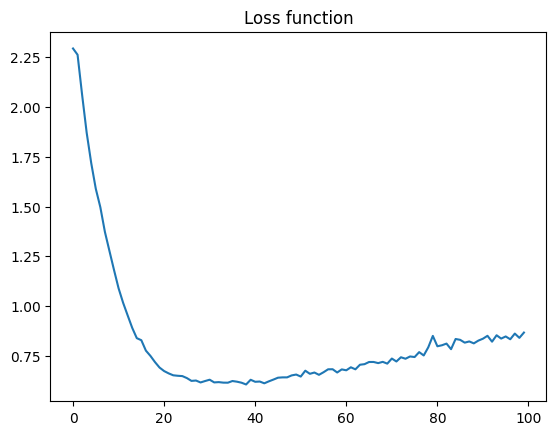

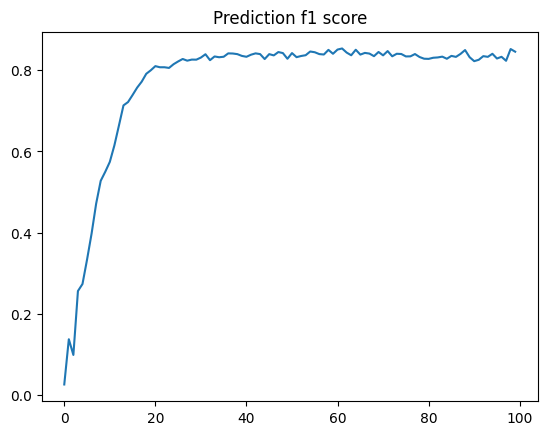

In [22]:
plt.plot(loss_list)
plt.title("Loss function")
plt.show()

plt.plot(f1_list)
plt.title("Prediction f1 score")
plt.show()
